# F1 Race Strategy Simulator and Predictor

This notebook uses four CSV files: `races.csv`, `results.csv`, `drivers.csv`, and `constructors.csv`.

**What it does**
1. Loads and checks the datasets.
2. Cleans missing values and merges the four tables.
3. Performs exploratory data analysis (EDA) with charts.
4. Creates historical driver/team features using only earlier races.
5. Trains models to predict finishing position and podium probability.
6. Provides a simple what-if simulator for a selected driver, team, and grid position.

> This is a historical baseline. The four files do not contain tyre compounds, tyre wear, fuel loads, pit-stop timing, or lap-by-lap data, so the simulator cannot yet optimize real pit-stop strategies.


## 1. Import libraries

Run this cell first. Google Colab already includes most of these libraries.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, accuracy_score, classification_report
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Upload the four CSV files

In Colab, click the folder icon on the left, choose **Upload**, and upload all four CSV files. Keep the filenames the same as below.

If the files are already in your Google Drive, you can mount Drive and change `DATA_FOLDER` to the folder containing them.

## 3. Read the data and inspect it

The original files use `\\N` for some missing values. We convert those markers to real missing values (`NaN`).

In [7]:
# Read the datasets directly from the uploaded files
races = pd.read_csv("races.csv")
results = pd.read_csv("results.csv")
drivers = pd.read_csv("drivers.csv")
constructors = pd.read_csv("constructors.csv")

# Group them into a dictionary for convenient data quality checks
datasets = {
    "races": races,
    "results": results,
    "drivers": drivers,
    "constructors": constructors
}

# Convert '\N' strings to true NaN values across all datasets
for name, data in datasets.items():
    data.replace("\\N", np.nan, inplace=True)

print("Data loaded and missing value markers converted successfully.")

Data loaded and missing value markers converted successfully.


## 4. Check data quality

We check column types, duplicate rows, missing values, and key IDs before merging.

In [8]:
for name, data in datasets.items():
    print(f"\\n--- {name.upper()} ---")
    print("Duplicate rows:", data.duplicated().sum())
    missing = data.isna().sum()
    print("Columns with missing values:")
    display(missing[missing > 0].sort_values(ascending=False).to_frame("missing_count").head(12))

print("Unique race IDs in races:", races["raceId"].nunique())
print("Unique result race IDs:", results["raceId"].nunique())
print("Unique driver IDs:", drivers["driverId"].nunique())
print("Unique constructor IDs:", constructors["constructorId"].nunique())

\n--- RACES ---
Duplicate rows: 0
Columns with missing values:


,missing_count
sprint_time,1110
sprint_date,1107
fp3_time,1072
quali_time,1057
fp2_time,1057
fp1_time,1057
fp3_date,1053
fp2_date,1035
fp1_date,1035
quali_date,1035


\n--- RESULTS ---
Duplicate rows: 0
Columns with missing values:


,missing_count
milliseconds,19079
time,19079
fastestLapTime,18507
fastestLap,18507
fastestLapSpeed,18507
rank,18249
position,10953
number,6


\n--- DRIVERS ---
Duplicate rows: 0
Columns with missing values:


,missing_count
number,802
code,757


\n--- CONSTRUCTORS ---
Duplicate rows: 0
Columns with missing values:


,missing_count


Unique race IDs in races: 1125
Unique result race IDs: 1125
Unique driver IDs: 861
Unique constructor IDs: 212


## 5. Merge all four datasets

The relationships are:
- `results.raceId` → `races.raceId`
- `results.driverId` → `drivers.driverId`
- `results.constructorId` → `constructors.constructorId`

We use left joins from `results` so every recorded race result is retained.

In [9]:
# Keep only useful descriptive columns from the lookup tables.
race_columns = ["raceId", "year", "round", "circuitId", "name", "date"]
driver_columns = ["driverId", "driverRef", "code", "forename", "surname", "nationality"]
constructor_columns = ["constructorId", "constructorRef", "name", "nationality"]

race_info = races[race_columns].rename(columns={"name": "race_name"})
driver_info = drivers[driver_columns].rename(columns={"nationality": "driver_nationality"})
constructor_info = constructors[constructor_columns].rename(
    columns={"name": "constructor_name", "nationality": "constructor_nationality"}
)

df = results.merge(race_info, on="raceId", how="left")
df = df.merge(driver_info, on="driverId", how="left")
df = df.merge(constructor_info, on="constructorId", how="left")

# Create readable names for reports and charts.
df["driver_name"] = (df["forename"].fillna("").astype(str) + " " +
                     df["surname"].fillna("").astype(str)).str.strip()

# Convert important numeric columns to numeric values.
numeric_columns = [
    "year", "round", "grid", "positionOrder", "points", "laps",
    "milliseconds", "fastestLapSpeed", "fastestLap", "rank"
]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.sort_values(["date", "raceId", "positionOrder"]).reset_index(drop=True)

print("Merged dataset shape:", df.shape)
display(df.head())
print("Years covered:", df["year"].min(), "to", df["year"].max())
print("Missing race names after merge:", df["race_name"].isna().sum())
print("Missing driver names after merge:", df["driver_name"].eq("").sum())

Merged dataset shape: (26759, 32)


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,year,round,circuitId,race_name,date,driverRef,code,forename,surname,driver_nationality,constructorRef,constructor_name,constructor_nationality,driver_name
0,20025,833,642,51,2,1,1,1,1,9.0,70,2:13:23.6,8003600.0,NaN,NaN,NaN,NaN,1,1950,1,9,British Grand Prix,1950-05-13,farina,NaN,Nino,Farina,Italian,alfa,Alfa Romeo,Swiss,Nino Farina
1,20026,833,786,51,3,2,2,2,2,6.0,70,+2.6,8006200.0,NaN,NaN,NaN,NaN,1,1950,1,9,British Grand Prix,1950-05-13,fagioli,NaN,Luigi,Fagioli,Italian,alfa,Alfa Romeo,Swiss,Luigi Fagioli
2,20027,833,686,51,4,4,3,3,3,4.0,70,+52.0,8055600.0,NaN,NaN,NaN,NaN,1,1950,1,9,British Grand Prix,1950-05-13,reg_parnell,NaN,Reg,Parnell,British,alfa,Alfa Romeo,Swiss,Reg Parnell
3,20028,833,704,154,14,6,4,4,4,3.0,68,NaN,NaN,NaN,NaN,NaN,NaN,12,1950,1,9,British Grand Prix,1950-05-13,cabantous,NaN,Yves,Cabantous,French,lago,Talbot-Lago,French,Yves Cabantous
4,20029,833,627,154,15,9,5,5,5,2.0,68,NaN,NaN,NaN,NaN,NaN,NaN,12,1950,1,9,British Grand Prix,1950-05-13,rosier,NaN,Louis,Rosier,French,lago,Talbot-Lago,French,Louis Rosier


Years covered: 1950 to 2024
Missing race names after merge: 0
Missing driver names after merge: 0


## 6. Save the merged dataset

This file can be downloaded and reused in the project.

In [10]:
df.to_csv("f1_merged_dataset.csv", index=False)
print("Saved: f1_merged_dataset.csv")

from google.colab import files
files.download("f1_merged_dataset.csv")

Saved: f1_merged_dataset.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Exploratory data analysis (EDA)

### 7.1 Number of races per year

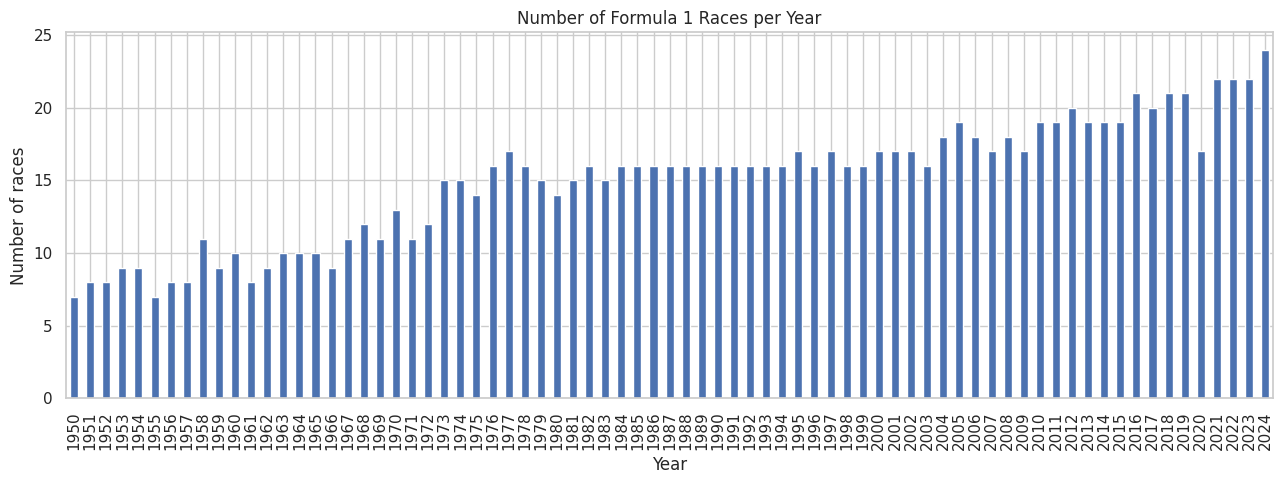

In [11]:
races_per_year = races.groupby("year")["raceId"].nunique()

plt.figure(figsize=(13, 5))
races_per_year.plot(kind="bar")
plt.title("Number of Formula 1 Races per Year")
plt.xlabel("Year")
plt.ylabel("Number of races")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### 7.2 Most successful drivers by championship points

Points systems changed over time, so this chart shows recorded points rather than a perfectly normalized comparison across eras.

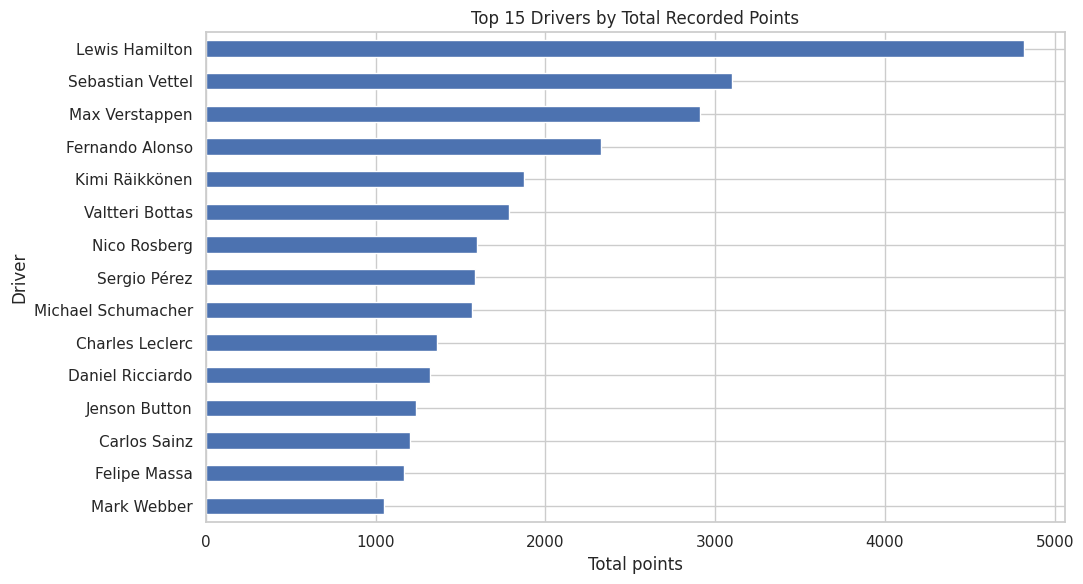

In [12]:
driver_points = (
    df.groupby("driver_name", dropna=True)["points"]
      .sum()
      .sort_values(ascending=False)
      .head(15)
)

plt.figure(figsize=(11, 6))
driver_points.sort_values().plot(kind="barh")
plt.title("Top 15 Drivers by Total Recorded Points")
plt.xlabel("Total points")
plt.ylabel("Driver")
plt.tight_layout()
plt.show()

### 7.3 Constructor performance

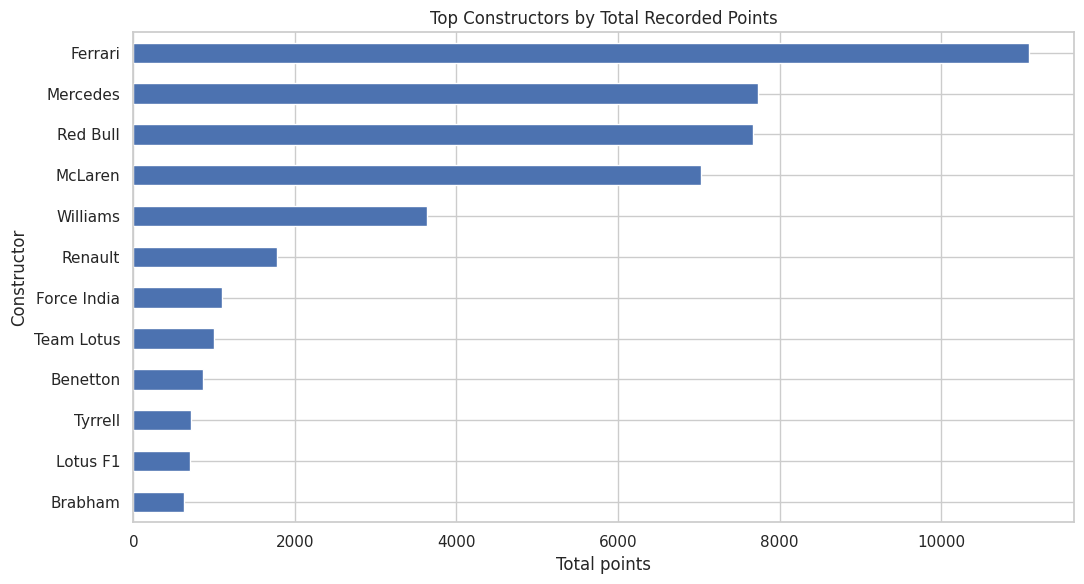

In [13]:
constructor_points = (
    df.groupby("constructor_name")["points"]
      .sum()
      .sort_values(ascending=False)
      .head(12)
)

plt.figure(figsize=(11, 6))
constructor_points.sort_values().plot(kind="barh")
plt.title("Top Constructors by Total Recorded Points")
plt.xlabel("Total points")
plt.ylabel("Constructor")
plt.tight_layout()
plt.show()

### 7.4 Starting grid versus finishing position

Lower position numbers are better. This plot helps show the relationship between starting position and final result.

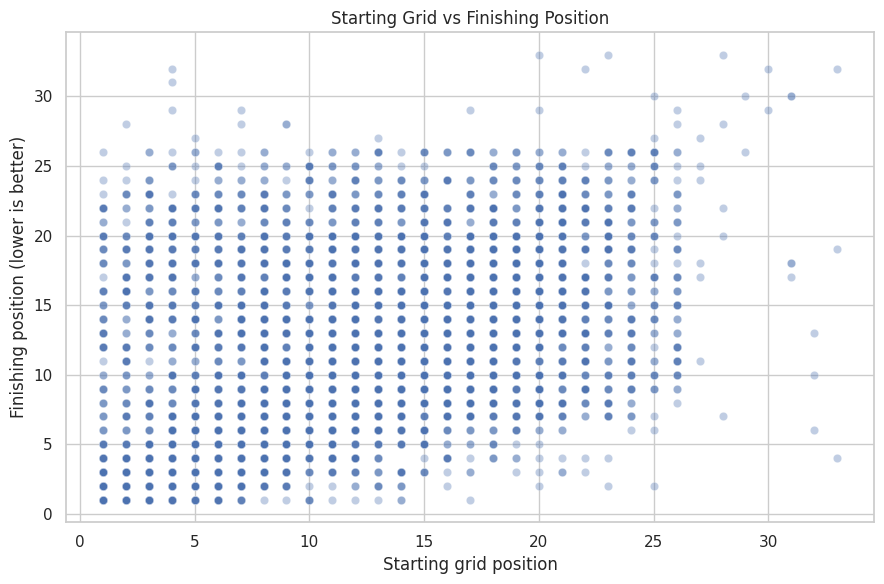

Correlation between grid and finishing position: 0.446


In [14]:
grid_plot = df.dropna(subset=["grid", "positionOrder"]).copy()
grid_plot = grid_plot[(grid_plot["grid"] > 0) & (grid_plot["positionOrder"] > 0)]

plt.figure(figsize=(9, 6))
sns.scatterplot(data=grid_plot.sample(min(5000, len(grid_plot)), random_state=42),
                x="grid", y="positionOrder", alpha=0.35)
plt.title("Starting Grid vs Finishing Position")
plt.xlabel("Starting grid position")
plt.ylabel("Finishing position (lower is better)")
plt.tight_layout()
plt.show()

print("Correlation between grid and finishing position:",
      round(grid_plot[["grid", "positionOrder"]].corr().iloc[0, 1], 3))

### 7.5 Finish status and race completion

The `statusId` field represents how a result ended. We show the most common statuses.

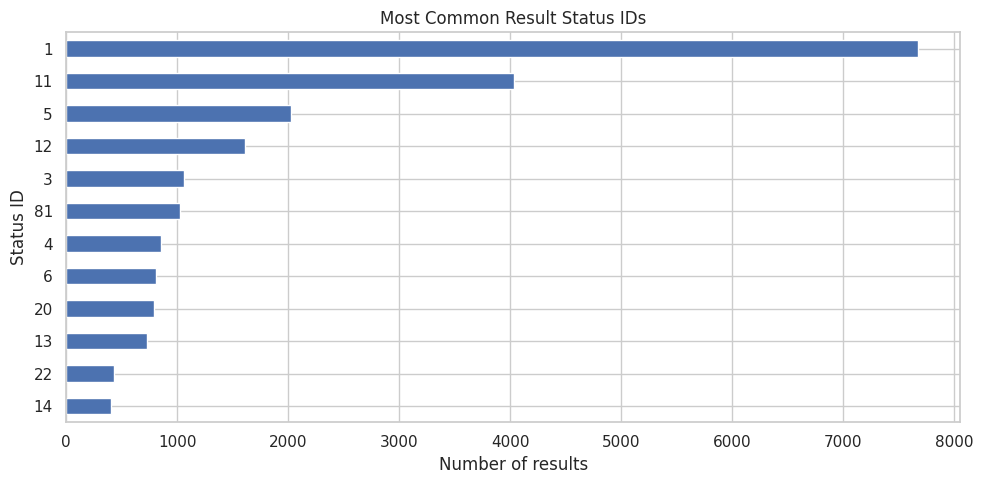

,statusId,positionText,positionOrder,laps
0,1,1,1,70
1,1,2,2,70
2,1,3,3,70
3,12,4,4,68
4,12,5,5,68
5,13,6,6,67
6,13,7,7,67
7,15,8,8,65
8,16,9,9,64
9,16,10,10,64


In [15]:
status_counts = df["statusId"].value_counts().head(12)

plt.figure(figsize=(10, 5))
status_counts.sort_values().plot(kind="barh")
plt.title("Most Common Result Status IDs")
plt.xlabel("Number of results")
plt.ylabel("Status ID")
plt.tight_layout()
plt.show()

display(df[["statusId", "positionText", "positionOrder", "laps"]].head(10))

## 8. Prepare data for machine learning

We predict `positionOrder` (the result order recorded by the dataset). To avoid data leakage, we do **not** use final race points, final position text, fastest lap, or other information that would only be known after the race.

We create historical driver and constructor features by shifting their previous results before calculating expanding averages. That means a race's prediction only uses data from earlier races.

In [16]:
model_df = df.copy()

# Keep rows with a usable target and starting grid.
model_df = model_df.dropna(subset=["positionOrder", "grid", "year", "raceId"]).copy()
model_df = model_df[model_df["grid"] > 0].copy()

# Sort chronologically before building previous-race features.
model_df = model_df.sort_values(["date", "raceId", "positionOrder"]).reset_index(drop=True)

# Previous performance for each driver: shift(1) prevents using the current race.
model_df["driver_previous_finish"] = (
    model_df.groupby("driverId")["positionOrder"].transform(lambda s: s.shift(1))
)
model_df["driver_avg_finish_before"] = (
    model_df.groupby("driverId")["positionOrder"]
    .transform(lambda s: s.shift(1).expanding().mean())
)
model_df["driver_avg_points_before"] = (
    model_df.groupby("driverId")["points"]
    .transform(lambda s: s.shift(1).expanding().mean())
)

# Previous performance for each constructor.
model_df["team_previous_finish"] = (
    model_df.groupby("constructorId")["positionOrder"].transform(lambda s: s.shift(1))
)
model_df["team_avg_finish_before"] = (
    model_df.groupby("constructorId")["positionOrder"]
    .transform(lambda s: s.shift(1).expanding().mean())
)
model_df["team_avg_points_before"] = (
    model_df.groupby("constructorId")["points"]
    .transform(lambda s: s.shift(1).expanding().mean())
)

# Replace missing history for drivers/teams at their first race.
# The imputer below will handle these missing feature values.
feature_columns = [
    "year", "round", "circuitId", "grid", "driverId", "constructorId",
    "driver_previous_finish", "driver_avg_finish_before",
    "driver_avg_points_before", "team_previous_finish",
    "team_avg_finish_before", "team_avg_points_before"
]

model_df = model_df.sort_values(["date", "raceId"]).reset_index(drop=True)

print("Rows available for modeling:", len(model_df))
display(model_df[feature_columns + ["positionOrder"]].head(10))

Rows available for modeling: 25121


,year,round,circuitId,grid,driverId,constructorId,driver_previous_finish,driver_avg_finish_before,driver_avg_points_before,team_previous_finish,team_avg_finish_before,team_avg_points_before,positionOrder
0,1950,1,9,1,642,51,NaN,NaN,NaN,NaN,NaN,NaN,1
1,1950,1,9,2,786,51,NaN,NaN,NaN,1.0,1.0,9.0,2
2,1950,1,9,4,686,51,NaN,NaN,NaN,2.0,1.5,7.5,3
3,1950,1,9,6,704,154,NaN,NaN,NaN,NaN,NaN,NaN,4
4,1950,1,9,9,627,154,NaN,NaN,NaN,4.0,4.0,3.0,5
5,1950,1,9,13,619,151,NaN,NaN,NaN,NaN,NaN,NaN,6
6,1950,1,9,15,787,151,NaN,NaN,NaN,6.0,6.0,0.0,7
7,1950,1,9,14,741,154,NaN,NaN,NaN,5.0,4.5,2.5,8
8,1950,1,9,16,784,105,NaN,NaN,NaN,NaN,NaN,NaN,9
9,1950,1,9,20,778,105,NaN,NaN,NaN,9.0,9.0,0.0,10


## 9. Train and evaluate the finishing-position predictor

We use a chronological split: older races for training and newer races for testing. This is more realistic than randomly mixing old and new races.

The model's output is an estimated finishing position. Since lower positions are better, compare errors as the average number of places off the recorded result.

In [17]:
# Use the latest 20% of race years as a holdout test period.
years = sorted(model_df["year"].dropna().unique())
split_index = max(1, int(len(years) * 0.8))
test_start_year = years[split_index]

train_data = model_df[model_df["year"] < test_start_year].copy()
test_data = model_df[model_df["year"] >= test_start_year].copy()

X_train = train_data[feature_columns]
y_train = train_data["positionOrder"]
X_test = test_data[feature_columns]
y_test = test_data["positionOrder"]

regressor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=250,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

regressor.fit(X_train, y_train)
position_predictions = regressor.predict(X_test)

mae = mean_absolute_error(y_test, position_predictions)
rmse = np.sqrt(mean_squared_error(y_test, position_predictions))

print("Training years:", int(train_data["year"].min()), "to", int(train_data["year"].max()))
print("Testing years:", int(test_data["year"].min()), "to", int(test_data["year"].max()))
print(f"Mean Absolute Error (positions): {mae:.2f}")
print(f"Root Mean Squared Error: {rmse:.2f}")

comparison = test_data[["year", "race_name", "driver_name", "constructor_name", "grid", "positionOrder"]].copy()
comparison["predicted_position"] = np.round(position_predictions, 1)
comparison = comparison.rename(columns={"positionOrder": "actual_position"})
display(comparison.head(20))

Training years: 1950 to 2009
Testing years: 2010 to 2024
Mean Absolute Error (positions): 4.02
Root Mean Squared Error: 4.91


,year,race_name,driver_name,constructor_name,grid,actual_position,predicted_position
18770,2010,Bahrain Grand Prix,Fernando Alonso,Ferrari,3,1,7.9
18771,2010,Bahrain Grand Prix,Felipe Massa,Ferrari,2,2,6.8
18772,2010,Bahrain Grand Prix,Lewis Hamilton,McLaren,4,3,6.7
18773,2010,Bahrain Grand Prix,Sebastian Vettel,Red Bull,1,4,5.6
18774,2010,Bahrain Grand Prix,Nico Rosberg,Mercedes,5,5,7.9
18775,2010,Bahrain Grand Prix,Michael Schumacher,Mercedes,7,6,9.2
18776,2010,Bahrain Grand Prix,Jenson Button,McLaren,8,7,9.0
18777,2010,Bahrain Grand Prix,Mark Webber,Red Bull,6,8,9.2
18778,2010,Bahrain Grand Prix,Vitantonio Liuzzi,Force India,12,9,13.3
18779,2010,Bahrain Grand Prix,Rubens Barrichello,Williams,11,10,10.6


## 10. Predict podium probability

A podium is defined here as a recorded finishing position from 1 to 3. We train a separate classifier and report its test accuracy and classification report. For an imbalanced target, also pay attention to precision and recall for the podium class.

In [18]:
train_data = train_data.copy()
test_data = test_data.copy()
train_data["podium"] = train_data["positionOrder"].between(1, 3).astype(int)
test_data["podium"] = test_data["positionOrder"].between(1, 3).astype(int)

podium_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=250,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

podium_model.fit(train_data[feature_columns], train_data["podium"])
podium_predictions = podium_model.predict(test_data[feature_columns])
podium_probabilities = podium_model.predict_proba(test_data[feature_columns])[:, 1]

print("Podium classification accuracy:", round(accuracy_score(test_data["podium"], podium_predictions), 3))
print(classification_report(test_data["podium"], podium_predictions,
                            target_names=["Not podium", "Podium"], zero_division=0))

podium_comparison = test_data[["year", "race_name", "driver_name", "constructor_name", "grid", "podium"]].copy()
podium_comparison["predicted_podium_probability"] = np.round(podium_probabilities, 3)
display(podium_comparison.sort_values("predicted_podium_probability", ascending=False).head(15))

Podium classification accuracy: 0.893
              precision    recall  f1-score   support

  Not podium       0.92      0.96      0.94      5436
      Podium       0.68      0.49      0.57       915

    accuracy                           0.89      6351
   macro avg       0.80      0.73      0.75      6351
weighted avg       0.88      0.89      0.89      6351



,year,race_name,driver_name,constructor_name,grid,podium,predicted_podium_probability
19082,2010,Italian Grand Prix,Fernando Alonso,Ferrari,1,1,0.801
19058,2010,Belgian Grand Prix,Lewis Hamilton,McLaren,2,1,0.783
22472,2018,Italian Grand Prix,Kimi Räikkönen,Ferrari,1,1,0.761
20772,2014,German Grand Prix,Nico Rosberg,Mercedes,1,1,0.746
18847,2010,Chinese Grand Prix,Sebastian Vettel,Red Bull,1,0,0.746
22942,2019,Japanese Grand Prix,Sebastian Vettel,Ferrari,1,1,0.745
19010,2010,German Grand Prix,Fernando Alonso,Ferrari,2,1,0.744
19916,2012,Hungarian Grand Prix,Lewis Hamilton,McLaren,1,1,0.740
19868,2012,British Grand Prix,Mark Webber,Red Bull,2,1,0.737
19964,2012,Italian Grand Prix,Lewis Hamilton,McLaren,1,1,0.733


## 10.1 Understanding model accuracy and evaluation

The notebook evaluates two different tasks, so the metrics are different:

- **Podium classification accuracy:** the fraction of test examples correctly classified as podium (finish 1st–3rd) or not podium. The exact value is printed by the classifier cell when you run the notebook.
- **Precision and recall:** precision tells us how many predicted podiums were actually podiums; recall tells us how many actual podium finishes the model found. These are important because podium finishes are much less common than non-podium finishes.
- **Mean Absolute Error (MAE):** the average absolute difference between the predicted and actual finishing positions. For example, an MAE of 2.4 means predictions are off by 2.4 places on average.
- **Root Mean Squared Error (RMSE):** like MAE, but penalizes larger mistakes more strongly.

**Important:** finishing position is a regression target, so a single classification-style “accuracy” score is not the best metric for it. Report MAE and RMSE for finishing-position prediction, and accuracy/precision/recall/F1 for podium classification. Do not write a numeric result into a report until you have run the notebook and copied the values printed from your test data.


## 11. See which features influenced the model

Feature importance is a rough indicator of which inputs the random forest used most. It does not prove causation.

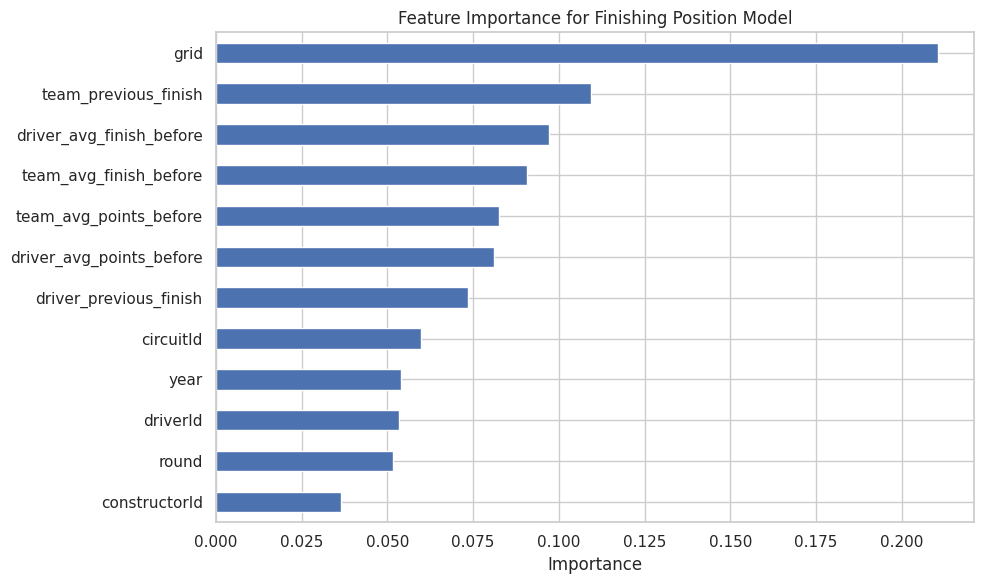

In [19]:
importance = pd.Series(
    regressor.named_steps["model"].feature_importances_,
    index=feature_columns
).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importance.plot(kind="barh")
plt.title("Feature Importance for Finishing Position Model")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 12. Build a simple race strategy simulator

This function lets you choose a driver, constructor, year, round, and starting grid position. It uses historical averages before the selected season/round to estimate driver and team form, then passes those features to the trained models.

This is a **what-if finishing outcome simulator**, not a tyre/pit-stop optimizer. The model uses the selected grid position as an input, so changing grid position lets you compare hypothetical starting scenarios.

In [20]:
def simulate_race(driver_name, constructor_name, year, round_number, grid_position):
    # Find the latest historical rows strictly before the requested race.
    earlier = model_df[
        (model_df["year"] < year) |
        ((model_df["year"] == year) & (model_df["round"] < round_number))
    ].copy()

    driver_history = earlier[earlier["driver_name"].str.lower() == driver_name.lower()]
    team_history = earlier[earlier["constructor_name"].str.lower() == constructor_name.lower()]

    # Use previous records where available. Otherwise the model imputer fills missing history.
    driver_previous_finish = driver_history["positionOrder"].iloc[-1] if len(driver_history) else np.nan
    driver_avg_finish = driver_history["positionOrder"].mean() if len(driver_history) else np.nan
    driver_avg_points = driver_history["points"].mean() if len(driver_history) else np.nan

    team_previous_finish = team_history["positionOrder"].iloc[-1] if len(team_history) else np.nan
    team_avg_finish = team_history["positionOrder"].mean() if len(team_history) else np.nan
    team_avg_points = team_history["points"].mean() if len(team_history) else np.nan

    # Use a circuit ID from the selected season/round when available.
    race_match = races[(races["year"] == year) & (races["round"] == round_number)]
    circuit_id = race_match["circuitId"].iloc[0] if len(race_match) else np.nan

    input_row = pd.DataFrame([{
        "year": year,
        "round": round_number,
        "circuitId": circuit_id,
        "grid": grid_position,
        "driverId": driver_history["driverId"].iloc[-1] if len(driver_history) else np.nan,
        "constructorId": team_history["constructorId"].iloc[-1] if len(team_history) else np.nan,
        "driver_previous_finish": driver_previous_finish,
        "driver_avg_finish_before": driver_avg_finish,
        "driver_avg_points_before": driver_avg_points,
        "team_previous_finish": team_previous_finish,
        "team_avg_finish_before": team_avg_finish,
        "team_avg_points_before": team_avg_points
    }])[feature_columns]

    predicted_position = float(regressor.predict(input_row)[0])
    podium_probability = float(podium_model.predict_proba(input_row)[0, 1])

    return {
        "Driver": driver_name,
        "Constructor": constructor_name,
        "Year": year,
        "Round": round_number,
        "Hypothetical grid position": grid_position,
        "Predicted finishing position": round(predicted_position, 1),
        "Estimated podium probability": f"{podium_probability:.1%}"
    }

# Example: replace these names with entries from your dataset.
print("Example drivers:", sorted(df["driver_name"].dropna().unique())[:15])
print("Example constructors:", sorted(df["constructor_name"].dropna().unique())[:15])

Example drivers: ['Adolf Brudes', 'Adolfo Cruz', 'Adrian Sutil', 'Adrián Campos', 'Aguri Suzuki', 'Al Herman', 'Al Keller', 'Al Pease', 'Alain Prost', 'Alain de Changy', 'Alan Brown', 'Alan Jones', 'Alan Rees', 'Alan Rollinson', 'Alan Stacey']
Example constructors: ['AFM', 'AGS', 'ATS', 'Adams', 'Alfa Romeo', 'AlphaTauri', 'Alpine F1 Team', 'Alta', 'Amon', 'Andrea Moda', 'Apollon', 'Arrows', 'Arzani-Volpini', 'Aston Butterworth', 'Aston Martin']


## 13. Run a simulation

Edit the values below using driver and constructor names from the printed lists. `year` and `round_number` should match a race in the races dataset; `grid_position` is the hypothetical starting place.

In [21]:
# EDIT THESE VALUES
chosen_driver = "Lewis Hamilton"
chosen_constructor = "Mercedes"
chosen_year = int(model_df["year"].max())
chosen_round = 1
chosen_grid = 5

simulation_result = simulate_race(
    driver_name=chosen_driver,
    constructor_name=chosen_constructor,
    year=chosen_year,
    round_number=chosen_round,
    grid_position=chosen_grid
)

display(pd.DataFrame([simulation_result]))

,Driver,Constructor,Year,Round,Hypothetical grid position,Predicted finishing position,Estimated podium probability
0,Lewis Hamilton,Mercedes,2024,1,5,8.0,30.9%


## 14. Compare different starting-grid scenarios

This table compares predicted outcomes for several hypothetical grid positions for the same driver and constructor.

In [22]:
grid_scenarios = [1, 3, 5, 10, 15, 20]
scenario_results = []

for grid_position in grid_scenarios:
    scenario_results.append(
        simulate_race(
            driver_name=chosen_driver,
            constructor_name=chosen_constructor,
            year=chosen_year,
            round_number=chosen_round,
            grid_position=grid_position
        )
    )

scenario_table = pd.DataFrame(scenario_results)
display(scenario_table)

,Driver,Constructor,Year,Round,Hypothetical grid position,Predicted finishing position,Estimated podium probability
0,Lewis Hamilton,Mercedes,2024,1,1,8.6,54.2%
1,Lewis Hamilton,Mercedes,2024,1,3,9.3,50.4%
2,Lewis Hamilton,Mercedes,2024,1,5,8.0,30.9%
3,Lewis Hamilton,Mercedes,2024,1,10,11.4,15.4%
4,Lewis Hamilton,Mercedes,2024,1,15,11.3,17.6%
5,Lewis Hamilton,Mercedes,2024,1,20,13.9,18.7%


## 15. Testing and validation

This section checks whether the dataset, trained models, evaluation outputs, and race simulator behave as expected. Run this section **after running the earlier notebook cells**, especially the model training and simulation cells.

The tests are basic project checks, not proof that every prediction is correct. Model quality is measured separately using MAE, RMSE, and podium classification metrics.


In [ ]:
# TEST 1: Check that the merged dataset contains the columns needed by the model.
required_columns = set(feature_columns + [
    "positionOrder", "raceId", "year", "driver_name", "constructor_name"
])
missing_columns = required_columns.difference(model_df.columns)
assert not missing_columns, f"Missing required columns: {missing_columns}"
print("PASS: Required model and dataset columns are present.")

# TEST 2: Check that the training and testing seasons do not overlap.
assert train_data["year"].max() < test_data["year"].min(), (
    "Training and testing seasons overlap. Use a chronological split."
)
print("PASS: Training seasons are earlier than testing seasons.")

# TEST 3: Check regression predictions and evaluation metrics.
assert len(position_predictions) == len(y_test), (
    "The number of finishing-position predictions does not match the test rows."
)
assert np.isfinite(position_predictions).all(), "Regression predictions contain NaN or infinite values."
assert np.isfinite(mae) and np.isfinite(rmse), "MAE or RMSE is not finite."
assert mae >= 0 and rmse >= 0, "MAE and RMSE should not be negative."
print(f"PASS: Regression predictions and metrics are valid (MAE={mae:.2f}, RMSE={rmse:.2f}).")

# TEST 4: Check podium classifier predictions and probabilities.
assert len(podium_predictions) == len(test_data), (
    "The number of podium predictions does not match the test rows."
)
assert set(np.unique(podium_predictions)).issubset({0, 1}), (
    "Podium predictions should contain only 0 (not podium) or 1 (podium)."
)
assert np.isfinite(podium_probabilities).all(), "Podium probabilities contain NaN or infinite values."
assert ((podium_probabilities >= 0) & (podium_probabilities <= 1)).all(), (
    "Podium probabilities must be between 0 and 1."
)
print(f"PASS: Podium predictions and probabilities are valid (accuracy={accuracy_score(test_data['podium'], podium_predictions):.2%}).")

# TEST 5: Check the race simulator's returned result.
assert isinstance(simulation_result, dict), "The simulator should return a dictionary."
expected_result_keys = {
    "Driver", "Constructor", "Year", "Round",
    "Hypothetical grid position", "Predicted finishing position",
    "Estimated podium probability"
}
assert expected_result_keys.issubset(simulation_result.keys()), (
    "The simulation result is missing one or more expected fields."
)
assert 1 <= int(simulation_result["Hypothetical grid position"]) <= 20, (
    "The hypothetical grid position should be between 1 and 20."
)
predicted_finish = float(simulation_result["Predicted finishing position"])
assert np.isfinite(predicted_finish), "Predicted finishing position is not finite."
probability_value = float(
    simulation_result["Estimated podium probability"].strip().replace("%", "")
)
assert 0 <= probability_value <= 100, "Podium probability should be between 0% and 100%."
print("PASS: Race simulator returns a valid prediction result.")

# TEST 6: Check the grid-scenario comparison table.
assert len(scenario_table) == len(grid_scenarios), (
    "The scenario table should contain one row for each tested grid position."
)
assert scenario_table["Hypothetical grid position"].tolist() == grid_scenarios, (
    "Scenario table grid positions do not match the requested scenarios."
)
print("PASS: Starting-grid scenario comparison contains all expected cases.")

print("\nAll automated checks passed.")


## 16. Export model-ready data

The merged file is useful for analysis. This second file contains the model features and target, making it easier to reuse the prepared dataset.

In [23]:
model_export_columns = feature_columns + ["positionOrder", "driver_name", "constructor_name", "race_name", "date"]
model_df[model_export_columns].to_csv("f1_model_ready_dataset.csv", index=False)
print("Saved f1_model_ready_dataset.csv")

from google.colab import files
files.download("f1_model_ready_dataset.csv")

Saved f1_model_ready_dataset.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. Conclusion

This project combines Formula 1 historical data from races, results, drivers, and constructors to explore racing trends and build two baseline machine-learning models. The Random Forest regressor estimates a driver's finishing position, while the Random Forest classifier estimates the probability of a podium finish. Historical driver and constructor features are shifted so that the current race result is not directly used as its own historical input, and the evaluation uses newer seasons as a holdout test period.

Use the printed test metrics to judge performance: MAE and RMSE describe finishing-position error, while podium accuracy, precision, recall, and F1 describe classification performance. These results should be treated as estimates rather than guaranteed predictions because race outcomes also depend on tyre strategy, pit stops, weather, safety cars, incidents, and other factors not included in the four CSV files.

The simulator is therefore a useful historical-data prototype and learning project, not yet a full pit-stop strategy optimizer. Future versions could add lap-level timing, tyre compounds and wear, pit-stop duration, weather, and safety-car data to compare realistic race strategies.


## 18. How to improve this project next

To move from a historical predictor to a more realistic F1 strategy simulator, add datasets with:
- Lap-by-lap timing and position.
- Tyre compound and tyre age for each stint.
- Pit-stop lap and pit-lane duration.
- Weather and track temperature.
- Safety-car and virtual-safety-car periods.
- Fuel load or a reasonable fuel-burn estimate.

Then you can simulate one-stop versus two-stop strategies, estimate stint pace and pit-loss, and compare expected race time under different safety-car scenarios.